# z006 - Elegir N: curvas de ganancia por semilla y Montecarlo de clientes

**Objetivo:** decidir cuántos clientes mandar (punto 2.3 del profesor).

1. **Curvas por semilla (tutoría):** mejor trial de z005 (trial 34) con las 5 semillas, curva promedio y su máximo.
2. **Ensamble:** los 8 mejores trials de z005 (promedio de 5 semillas) promediando probabilidades → su curva.
3. **Montecarlo de clientes:** 200 veces se toma un 25% al azar de los clientes de 202106 (como el leaderboard público)
   y se calcula la ganancia de cada N. Sirve para ver cuánto ruido tiene el público y qué N es más estable.

Train 202104, valid 202106, variables con lags 1 y 2, receta del profesor.

In [1]:
# --- 1. Librerías y parámetros ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO   = 27_500
MESES_TRAIN = [202104]
MES_VALID   = 202106
SEMILLA     = 501419
SEMILLAS    = [501419, 623353, 786349, 834569, 946331]
CORTES      = [10_000, 10_500, 11_000, 11_500, 12_000, 12_500, 13_000, 13_500, 14_000]
N_MONTECARLO = 200
TOP_TRIALS  = 8   # cuántos trials de z005 entran en el ensamble

params_fijos = {
    "objective": "binary", "metric": "auc", "learning_rate": 0.005,
    "min_data_in_leaf": 0, "feature_fraction": 0.5, "feature_fraction_bynode": 0.2,
    "max_bin": 31, "verbose": -1,
}

# Ranking de z005 (ordenado por el promedio de 5 semillas)
ranking = pd.read_csv("z005_top10_5semillas.csv", sep=";", decimal=",", encoding="utf-8-sig", index_col="trial")
ranking[["params_num_leaves", "params_min_sum_hessian_in_leaf", "user_attrs_best_iter", "ganancia_max_M_mean"]]

,params_num_leaves,params_min_sum_hessian_in_leaf,user_attrs_best_iter,ganancia_max_M_mean
trial,,,,
34,137,9.755574,538,399.6
36,61,7.745374,727,395.5
27,241,5.632060,578,394.6
29,193,5.968488,567,394.5
37,240,0.003039,888,393.6
9,65,1.250592,684,392.5
21,231,1.240045,648,390.3
24,250,2.344906,572,386.7
6,37,0.003192,868,377.5


In [2]:
# --- 2. Cargar datos, target y lags (igual que z003) ---
df = pd.read_parquet("../competencia_01.parquet")
df["clase_binaria"] = (df["clase_ternaria"] == "BAJA+2").astype(int)

no_usar = ["foto_mes", "clase_ternaria", "clase_binaria"]
originales = [c for c in df.columns if c not in no_usar]
cols = [c for c in originales if c != "numero_de_cliente"]

df = df.sort_values(["numero_de_cliente", "foto_mes"]).reset_index(drop=True)
grupo = df.groupby("numero_de_cliente")[cols]
nuevas = []
for k in [1, 2]:
    lag = grupo.shift(k).astype("float32")
    delta = (df[cols] - lag).astype("float32")
    lag.columns   = [f"{c}_lag{k}" for c in cols]
    delta.columns = [f"{c}_delta{k}" for c in cols]
    nuevas += [lag, delta]
df = pd.concat([df] + nuevas, axis=1)
del nuevas, lag, delta, grupo

variables = [c for c in df.columns if c not in no_usar]
train = df[df["foto_mes"].isin(MESES_TRAIN)]
valid = df[df["foto_mes"] == MES_VALID]
y_valid = valid["clase_binaria"].values
ganancia_cliente = np.where(y_valid == 1, GANANCIA_ACIERTO, -COSTO_ESTIMULO)
datos_train = lgb.Dataset(train[variables], label=train["clase_binaria"], free_raw_data=False)

def params_trial(trial):
    r = ranking.loc[trial]
    p = {**params_fijos, "num_leaves": int(r["params_num_leaves"]),
         "min_sum_hessian_in_leaf": float(r["params_min_sum_hessian_in_leaf"])}
    return p, int(r["user_attrs_best_iter"])

def curva(prob):
    # Ganancia acumulada ordenando de mayor a menor probabilidad
    return np.cumsum(ganancia_cliente[np.argsort(prob)[::-1]])

Semilla 501419 lista


Semilla 623353 lista


Semilla 786349 lista


Semilla 834569 lista


Semilla 946331 lista


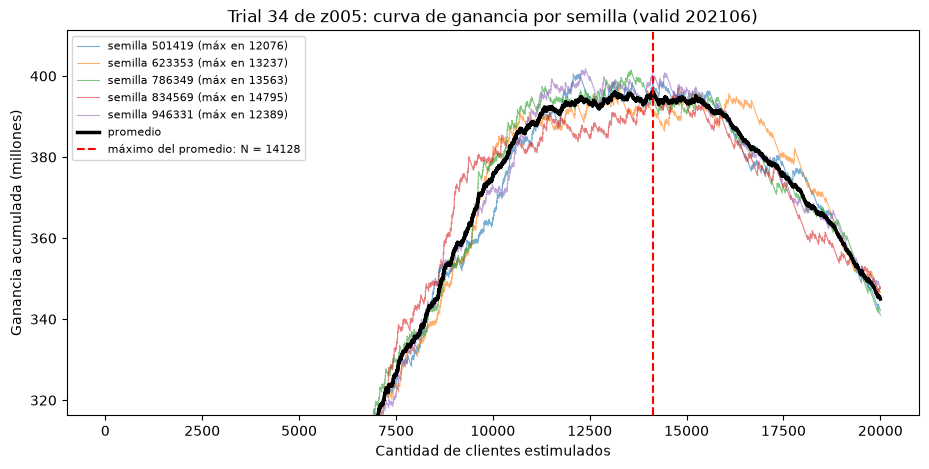

Máximo de la curva promedio: N = 14128, ganancia = 396.2 M


In [3]:
# --- 3. Mejor trial con las 5 semillas: curvas y curva promedio ---
mejor_trial = ranking.index[0]
p, arboles = params_trial(mejor_trial)

probs_semillas = {}
for semilla in SEMILLAS:
    modelo = lgb.train({**p, "seed": semilla}, datos_train, num_boost_round=arboles)
    probs_semillas[semilla] = modelo.predict(valid[variables])
    print("Semilla", semilla, "lista")

curvas = np.array([curva(pr) for pr in probs_semillas.values()]) / 1e6
curva_prom = curvas.mean(axis=0)
n_prom = int(np.argmax(curva_prom)) + 1

limite = 20_000
x = np.arange(1, limite + 1)
plt.figure(figsize=(11, 5))
for s, c in zip(SEMILLAS, curvas):
    plt.plot(x, c[:limite], linewidth=0.8, alpha=0.6, label=f"semilla {s} (máx en {np.argmax(c) + 1})")
plt.plot(x, curva_prom[:limite], color="black", linewidth=2.5, label="promedio")
plt.axvline(n_prom, color="red", linestyle="--", label=f"máximo del promedio: N = {n_prom}")
plt.ylim(curva_prom[:limite].max() - 80, curva_prom[:limite].max() + 15)
plt.xlabel("Cantidad de clientes estimulados")
plt.ylabel("Ganancia acumulada (millones)")
plt.title(f"Trial {mejor_trial} de z005: curva de ganancia por semilla (valid 202106)")
plt.legend(fontsize=8)
plt.savefig("z006_curvas_semillas.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Máximo de la curva promedio: N = {n_prom}, ganancia = {curva_prom[n_prom - 1]:.1f} M")

In [4]:
# --- 4. Ensamble de los mejores trials (semilla 501419) ---
probs_trials = {}
for trial in ranking.index[:TOP_TRIALS]:
    p, arboles = params_trial(trial)
    modelo = lgb.train({**p, "seed": SEMILLA}, datos_train, num_boost_round=arboles)
    probs_trials[trial] = modelo.predict(valid[variables])
    print("Trial", trial, "listo")

prob_ensamble = np.mean(list(probs_trials.values()), axis=0)
curva_ens = curva(prob_ensamble) / 1e6
n_ens = int(np.argmax(curva_ens)) + 1
print(f"Ensamble de {TOP_TRIALS} trials: máximo en N = {n_ens}, ganancia = {curva_ens[n_ens - 1]:.1f} M")
print("Cada trial solo (semilla 501419), ganancia máx:",
      {t: round(curva(pr).max() / 1e6, 1) for t, pr in probs_trials.items()})

# Guardamos las probabilidades para no reentrenar si hace falta
pd.DataFrame({"numero_de_cliente": valid["numero_de_cliente"].values, "clase_binaria": y_valid,
              "prob_ensamble": prob_ensamble}).to_parquet("z006_prob_ensamble_202106.parquet")

Trial 34 listo


Trial 36 listo


Trial 27 listo


Trial 29 listo


Trial 37 listo


Trial 9 listo


Trial 21 listo


Trial 24 listo
Ensamble de 8 trials: máximo en N = 11628, ganancia = 399.6 M
Cada trial solo (semilla 501419), ganancia máx: {34: np.float64(400.5), 36: np.float64(397.4), 27: np.float64(399.4), 29: np.float64(393.3), 37: np.float64(395.6), 9: np.float64(393.2), 21: np.float64(398.6), 24: np.float64(395.3)}


In [5]:
# --- 5. Montecarlo de clientes: simular el leaderboard público (25% de los clientes) ---
rng = np.random.default_rng(SEMILLA)
orden = np.argsort(prob_ensamble)[::-1]   # ranking del ensamble
n_clientes = len(y_valid)

filas = []
for i in range(N_MONTECARLO):
    publico = rng.random(n_clientes) < 0.25          # True = el cliente cae en el "público"
    for n in CORTES:
        elegidos = orden[:n]                          # los N que mandaríamos
        en_publico = elegidos[publico[elegidos]]      # de esos, los que cuentan en el público
        filas.append({"muestra": i, "N": n, "ganancia_publica_M": ganancia_cliente[en_publico].sum() / 1e6})

mc = pd.DataFrame(filas)
resumen_mc = mc.groupby("N")["ganancia_publica_M"].agg(["mean", "std", "min", "max"]).round(1)

# ¿En cuántas muestras gana cada N?
ganador = mc.loc[mc.groupby("muestra")["ganancia_publica_M"].idxmax(), "N"].value_counts()
resumen_mc["veces_mejor_N"] = ganador.reindex(resumen_mc.index).fillna(0).astype(int)
resumen_mc["ganancia_total_M"] = [round(curva_ens[n - 1], 1) for n in resumen_mc.index]
resumen_mc

,mean,std,min,max,veces_mejor_N,ganancia_total_M
N,,,,,,
10000,96.9,11.6,63.3,134.8,12,383.9
10500,97.7,11.6,63.8,137.8,7,387.8
11000,98.7,11.8,64.3,137.4,11,390.5
11500,100.6,12.0,66.3,139.4,49,397.6
12000,100.6,12.2,67.5,139.5,39,397.1
12500,99.5,12.4,64.4,139.0,8,393.2
13000,99.4,12.6,64.2,138.3,16,391.6
13500,99.2,12.7,63.9,138.5,15,390.0
14000,99.6,12.6,65.8,137.1,43,391.6


<Figure size 1000x400 with 0 Axes>

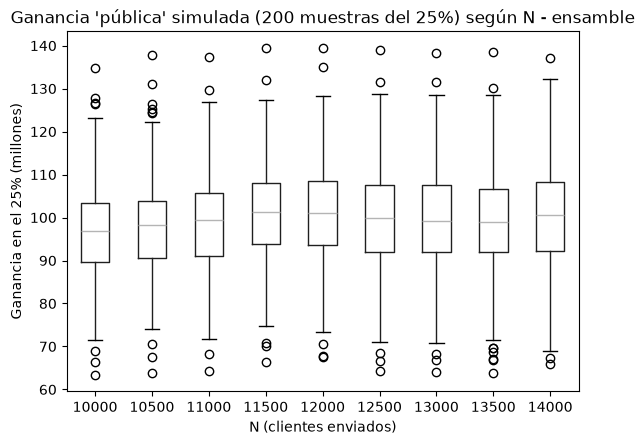

Desvío del público para un mismo N (promedio): 12.2 M


In [6]:
# --- 6. Gráfico del Montecarlo ---
plt.figure(figsize=(10, 4))
mc.boxplot(column="ganancia_publica_M", by="N", grid=False)
plt.suptitle("")
plt.title(f"Ganancia 'pública' simulada ({N_MONTECARLO} muestras del 25%) según N - ensamble")
plt.xlabel("N (clientes enviados)")
plt.ylabel("Ganancia en el 25% (millones)")
plt.savefig("z006_montecarlo.png", dpi=120, bbox_inches="tight")
plt.show()

# ¿Cuánto cambia el público entre dos muestras, con el mismo archivo?
print("Desvío del público para un mismo N (promedio):", round(resumen_mc["std"].mean(), 1), "M")